In [1]:
import sys

In [2]:
print(sys.executable)

/Users/jenniferho/Documents/Portfolio/projects/healthcare-access/.venv/bin/python


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [5]:
df = pd.read_csv("../data/raw/export.csv")

In [6]:
df.head()

,StateAbbr,StateDesc,CountyName,CountyFIPS,TractFIPS,TotalPopulation,TotalPop18plus,ACCESS2_CrudePrev,ACCESS2_Crude95CI,ARTHRITIS_CrudePrev,...,FOODINSECU_Crude95CI,HOUSINSECU_CrudePrev,HOUSINSECU_Crude95CI,SHUTUTILITY_CrudePrev,SHUTUTILITY_Crude95CI,LACKTRPT_CrudePrev,LACKTRPT_Crude95CI,EMOTIONSPT_CrudePrev,EMOTIONSPT_Crude95CI,Geolocation
0,AL,Alabama,Autauga,1001,1001020100,1775,"1,370",11.2,"( 8.7, 14.2)",35.2,...,"(14.9, 18.6)",14.2,"(12.5, 16.0)",9.3,"( 8.1, 10.6)",9.7,"( 8.8, 10.7)",25.9,"(22.4, 29.7)",POINT (-86.4915648 32.4819731)
1,AL,Alabama,Autauga,1001,1001020200,2055,"1,584",10.7,"( 8.6, 12.9)",32.3,...,"(19.1, 23.5)",19.1,"(17.1, 21.3)",12.1,"(10.7, 13.8)",11.4,"(10.4, 12.6)",30.7,"(27.0, 34.9)",POINT (-86.4724678 32.475758)
2,AL,Alabama,Autauga,1001,1001020300,3216,"2,485",10.9,"( 8.7, 13.5)",35.7,...,"(15.2, 18.9)",15.0,"(13.3, 16.8)",9.8,"( 8.7, 11.2)",9.8,"( 9.0, 10.9)",25.9,"(22.4, 29.6)",POINT (-86.4597033 32.4740243)
3,AL,Alabama,Autauga,1001,1001020400,4246,"3,344",8.4,"( 6.5, 10.8)",37.0,...,"(11.1, 14.0)",10.7,"( 9.5, 12.1)",6.9,"( 6.0, 7.8)",7.6,"( 6.9, 8.4)",24.7,"(21.4, 28.5)",POINT (-86.4448353 32.4710304)
4,AL,Alabama,Autauga,1001,1001020501,4322,"3,369",7.9,"( 6.1, 10.3)",32.3,...,"( 8.9, 11.4)",9.6,"( 8.5, 10.9)",6.2,"( 5.4, 7.1)",6.5,"( 5.9, 7.3)",23.1,"(19.9, 26.6)",POINT (-86.4225578 32.4478607)


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 83522 entries, 0 to 83521
Data columns (total 88 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   StateAbbr               83522 non-null  str    
 1   StateDesc               83522 non-null  str    
 2   CountyName              83522 non-null  str    
 3   CountyFIPS              83522 non-null  int64  
 4   TractFIPS               83522 non-null  int64  
 5   TotalPopulation         83522 non-null  int64  
 6   TotalPop18plus          83522 non-null  str    
 7   ACCESS2_CrudePrev       83522 non-null  float64
 8   ACCESS2_Crude95CI       83522 non-null  str    
 9   ARTHRITIS_CrudePrev     83522 non-null  float64
 10  ARTHRITIS_Crude95CI     83522 non-null  str    
 11  BINGE_CrudePrev         83522 non-null  float64
 12  BINGE_Crude95CI         83522 non-null  str    
 13  BPHIGH_CrudePrev        78445 non-null  float64
 14  BPHIGH_Crude95CI        78445 non-null  str    
 

In [8]:
df.columns.tolist()

['StateAbbr',
 'StateDesc',
 'CountyName',
 'CountyFIPS',
 'TractFIPS',
 'TotalPopulation',
 'TotalPop18plus',
 'ACCESS2_CrudePrev',
 'ACCESS2_Crude95CI',
 'ARTHRITIS_CrudePrev',
 'ARTHRITIS_Crude95CI',
 'BINGE_CrudePrev',
 'BINGE_Crude95CI',
 'BPHIGH_CrudePrev',
 'BPHIGH_Crude95CI',
 'BPMED_CrudePrev',
 'BPMED_Crude95CI',
 'CANCER_CrudePrev',
 'CANCER_Crude95CI',
 'CASTHMA_CrudePrev',
 'CASTHMA_Crude95CI',
 'CHD_CrudePrev',
 'CHD_Crude95CI',
 'CHECKUP_CrudePrev',
 'CHECKUP_Crude95CI',
 'CHOLSCREEN_CrudePrev',
 'CHOLSCREEN_Crude95CI',
 'COLON_SCREEN_CrudePrev',
 'COLON_SCREEN_Crude95CI',
 'COPD_CrudePrev',
 'COPD_Crude95CI',
 'CSMOKING_CrudePrev',
 'CSMOKING_Crude95CI',
 'DENTAL_CrudePrev',
 'DENTAL_Crude95CI',
 'DEPRESSION_CrudePrev',
 'DEPRESSION_Crude95CI',
 'DIABETES_CrudePrev',
 'DIABETES_Crude95CI',
 'GHLTH_CrudePrev',
 'GHLTH_Crude95CI',
 'HIGHCHOL_CrudePrev',
 'HIGHCHOL_Crude95CI',
 'LPA_CrudePrev',
 'LPA_Crude95CI',
 'MAMMOUSE_CrudePrev',
 'MAMMOUSE_Crude95CI',
 'MHLTH_CrudePr

In [10]:
keep_cols = [
    # Geography / population
    "StateAbbr",
    "StateDesc",
    "CountyName",
    "CountyFIPS",
    "TractFIPS",
    "TotalPopulation",
    "TotalPop18plus",
    "Geolocation",

    # Chronic disease / health need
    "DIABETES_CrudePrev",
    "COPD_CrudePrev",
    "CHD_CrudePrev",
    "STROKE_CrudePrev",
    "BPHIGH_CrudePrev",
    "HIGHCHOL_CrudePrev",
    "CASTHMA_CrudePrev",
    "ARTHRITIS_CrudePrev",
    "GHLTH_CrudePrev",
    "PHLTH_CrudePrev",
    "DISABILITY_CrudePrev",

    # Primary care / preventive care outcomes
    "CHECKUP_CrudePrev",
    "CHOLSCREEN_CrudePrev",
    "BPMED_CrudePrev",

    # Healthcare access barriers
    "ACCESS2_CrudePrev",
    "LACKTRPT_CrudePrev",

    # Major behavioral risk factors
    "CSMOKING_CrudePrev",
    "OBESITY_CrudePrev",
    "LPA_CrudePrev",
    "BINGE_CrudePrev",

    # Mental / social factors
    "DEPRESSION_CrudePrev",
    "MHLTH_CrudePrev",
    "ISOLATION_CrudePrev",
    "EMOTIONSPT_CrudePrev",

    # Economic / material hardship
    "FOODSTAMP_CrudePrev",
    "FOODINSECU_CrudePrev",
    "HOUSINSECU_CrudePrev",
    "SHUTUTILITY_CrudePrev"
]

df_small = df[keep_cols].copy()

In [11]:
df_small.shape

(83522, 36)

In [12]:
df_small.info()

<class 'pandas.DataFrame'>
RangeIndex: 83522 entries, 0 to 83521
Data columns (total 36 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   StateAbbr              83522 non-null  str    
 1   StateDesc              83522 non-null  str    
 2   CountyName             83522 non-null  str    
 3   CountyFIPS             83522 non-null  int64  
 4   TractFIPS              83522 non-null  int64  
 5   TotalPopulation        83522 non-null  int64  
 6   TotalPop18plus         83522 non-null  str    
 7   Geolocation            83522 non-null  str    
 8   DIABETES_CrudePrev     83522 non-null  float64
 9   COPD_CrudePrev         83522 non-null  float64
 10  CHD_CrudePrev          83522 non-null  float64
 11  STROKE_CrudePrev       83522 non-null  float64
 12  BPHIGH_CrudePrev       78445 non-null  float64
 13  HIGHCHOL_CrudePrev     78445 non-null  float64
 14  CASTHMA_CrudePrev      83522 non-null  float64
 15  ARTHRITIS_Cru

In [13]:
df_small.isna().sum().sort_values(ascending=False)

SHUTUTILITY_CrudePrev    19635
HOUSINSECU_CrudePrev     19635
FOODINSECU_CrudePrev     19635
FOODSTAMP_CrudePrev      19635
EMOTIONSPT_CrudePrev     19635
ISOLATION_CrudePrev      19635
LACKTRPT_CrudePrev       19635
BPHIGH_CrudePrev          5077
BPMED_CrudePrev           5077
HIGHCHOL_CrudePrev        5077
CHOLSCREEN_CrudePrev      5077
OBESITY_CrudePrev            0
LPA_CrudePrev                0
CHECKUP_CrudePrev            0
CSMOKING_CrudePrev           0
DEPRESSION_CrudePrev         0
ACCESS2_CrudePrev            0
MHLTH_CrudePrev              0
BINGE_CrudePrev              0
StateAbbr                    0
StateDesc                    0
PHLTH_CrudePrev              0
GHLTH_CrudePrev              0
ARTHRITIS_CrudePrev          0
CASTHMA_CrudePrev            0
STROKE_CrudePrev             0
CHD_CrudePrev                0
COPD_CrudePrev               0
DIABETES_CrudePrev           0
Geolocation                  0
TotalPop18plus               0
TotalPopulation              0
TractFIP

In [14]:
df_small.loc[
    df_small["FOODINSECU_CrudePrev"].isna(),
    "StateAbbr"
].value_counts()

StateAbbr
NY    5289
PA    3408
IL    3258
VA    2166
CO    1437
LA    1367
OR     993
AR     821
HI     426
SD     242
ND     228
Name: count, dtype: int64

In [15]:
df_small.loc[
    df_small["BPHIGH_CrudePrev"].isna(),
    "StateAbbr"
].value_counts()

StateAbbr
FL    5077
Name: count, dtype: int64

In [16]:
social_cols = [
    "FOODSTAMP_CrudePrev",
    "FOODINSECU_CrudePrev",
    "HOUSINSECU_CrudePrev",
    "SHUTUTILITY_CrudePrev",
    "LACKTRPT_CrudePrev",
    "ISOLATION_CrudePrev",
    "EMOTIONSPT_CrudePrev"
]

df_small[social_cols].isna().sum()

FOODSTAMP_CrudePrev      19635
FOODINSECU_CrudePrev     19635
HOUSINSECU_CrudePrev     19635
SHUTUTILITY_CrudePrev    19635
LACKTRPT_CrudePrev       19635
ISOLATION_CrudePrev      19635
EMOTIONSPT_CrudePrev     19635
dtype: int64

In [17]:
core_need_cols = [
    "DIABETES_CrudePrev",
    "COPD_CrudePrev",
    "CHD_CrudePrev",
    "STROKE_CrudePrev",
    "GHLTH_CrudePrev",
    "PHLTH_CrudePrev",
    "DISABILITY_CrudePrev",
    "OBESITY_CrudePrev",
    "LPA_CrudePrev",
    "CSMOKING_CrudePrev",
    "DEPRESSION_CrudePrev",
    "MHLTH_CrudePrev"
]

outcome_cols = [
    "CHECKUP_CrudePrev"
]

In [18]:
context_cols = [
    "FOODSTAMP_CrudePrev",
    "FOODINSECU_CrudePrev",
    "HOUSINSECU_CrudePrev",
    "SHUTUTILITY_CrudePrev",
    "LACKTRPT_CrudePrev",
    "ISOLATION_CrudePrev",
    "EMOTIONSPT_CrudePrev"
]

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [20]:
X_need = df_small[core_need_cols].copy()

In [21]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_need)

In [22]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

In [23]:
pca.explained_variance_ratio_

array([0.73103945, 0.1264315 , 0.06987943, 0.03017194, 0.01483633,
       0.00869886, 0.00705421, 0.00443181, 0.0028104 , 0.00219919,
       0.00151176, 0.00093514])

In [24]:
pca.explained_variance_ratio_.cumsum()

array([0.73103945, 0.85747095, 0.92735037, 0.95752231, 0.97235864,
       0.98105751, 0.98811171, 0.99254352, 0.99535392, 0.9975531 ,
       0.99906486, 1.        ])

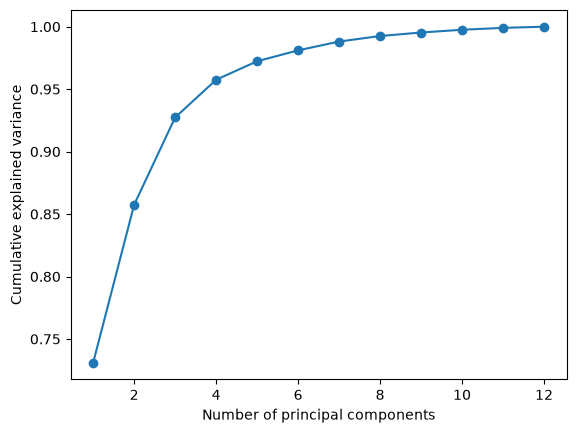

In [25]:
import matplotlib.pyplot as plt

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    pca.explained_variance_ratio_.cumsum(),
    marker="o"
)

plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.show()

In [26]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=core_need_cols,
    columns=[f"PC{i+1}" for i in range(len(core_need_cols))]
)

loadings[["PC1", "PC2"]].sort_values("PC1", ascending=False)

,PC1,PC2
PHLTH_CrudePrev,0.327907,-0.005225
DISABILITY_CrudePrev,0.326871,0.055024
GHLTH_CrudePrev,0.315994,0.036617
LPA_CrudePrev,0.314606,-0.000073
CSMOKING_CrudePrev,0.311005,0.158841
COPD_CrudePrev,0.305405,-0.124805
STROKE_CrudePrev,0.302453,-0.296944
DIABETES_CrudePrev,0.299397,-0.285403
OBESITY_CrudePrev,0.281421,0.125868
CHD_CrudePrev,0.246462,-0.407890


In [27]:
df_small["NeedScore"] = X_pca[:, 0]

In [28]:
df_small["NeedScore"].describe()

count    8.352200e+04
mean     1.306714e-16
std      2.961854e+00
min     -8.037040e+00
25%     -2.138514e+00
50%     -3.070372e-01
75%      1.782804e+00
max      1.761404e+01
Name: NeedScore, dtype: float64

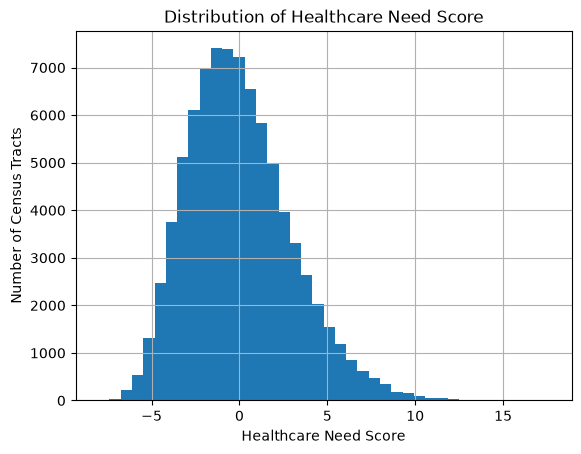

In [29]:
df_small["NeedScore"].hist(bins=40)
plt.xlabel("Healthcare Need Score")
plt.ylabel("Number of Census Tracts")
plt.title("Distribution of Healthcare Need Score")
plt.show()

In [30]:
df_small[
    ["StateAbbr", "CountyName", "TractFIPS", "NeedScore"]
].sort_values("NeedScore", ascending=False).head(10)

,StateAbbr,CountyName,TractFIPS,NeedScore
52830,NY,Queens,36081042600,17.614039
40423,MI,Wayne,26163983400,17.057396
61284,OK,Oklahoma,40109980009,16.503982
57821,OH,Cuyahoga,39035112100,16.088381
71868,TX,El Paso,48141001800,15.975135
32009,KY,Jefferson,21111005901,15.088118
71870,TX,El Paso,48141002000,14.893410
11420,CA,San Francisco,6075980501,14.656270
32866,LA,Caddo,22017023802,14.479415
49166,NM,Socorro,35053940000,14.363060


In [31]:
df_small[
    ["StateAbbr", "CountyName", "TractFIPS", "NeedScore"]
].sort_values("NeedScore").head(10)

,StateAbbr,CountyName,TractFIPS,NeedScore
47386,NJ,Hudson,34017007702,-8.037040
12121,CA,Santa Clara,6085505012,-7.810673
12105,CA,Santa Clara,6085504509,-7.735513
47385,NJ,Hudson,34017007701,-7.660652
79971,WA,King,53033006701,-7.633314
47383,NJ,Hudson,34017007601,-7.628715
52556,NY,Queens,36081001902,-7.462055
47384,NJ,Hudson,34017007602,-7.382371
51722,NY,Nassau,36059980100,-7.356620
47380,NJ,Hudson,34017007300,-7.337737


In [32]:
compare_cols = [
    "StateAbbr",
    "CountyName",
    "TractFIPS",
    "NeedScore",
    "DIABETES_CrudePrev",
    "COPD_CrudePrev",
    "CHD_CrudePrev",
    "STROKE_CrudePrev",
    "GHLTH_CrudePrev",
    "PHLTH_CrudePrev",
    "DISABILITY_CrudePrev",
    "OBESITY_CrudePrev",
    "LPA_CrudePrev",
    "CSMOKING_CrudePrev",
    "DEPRESSION_CrudePrev",
    "MHLTH_CrudePrev"
]

In [33]:
df_small[compare_cols].sort_values("NeedScore", ascending=False).head(5)

,StateAbbr,CountyName,TractFIPS,NeedScore,DIABETES_CrudePrev,COPD_CrudePrev,CHD_CrudePrev,STROKE_CrudePrev,GHLTH_CrudePrev,PHLTH_CrudePrev,DISABILITY_CrudePrev,OBESITY_CrudePrev,LPA_CrudePrev,CSMOKING_CrudePrev,DEPRESSION_CrudePrev,MHLTH_CrudePrev
52830,NY,Queens,36081042600,17.614039,44.7,25.2,37.1,22.6,53.9,32.1,69.5,39.2,59.6,18.3,9.9,11.5
40423,MI,Wayne,26163983400,17.057396,26.8,34.9,28.2,18.6,52.9,35.5,72.1,35.2,55.0,21.1,28.2,24.9
61284,OK,Oklahoma,40109980009,16.503982,29.9,24.9,16.9,11.7,59.0,33.8,68.4,60.5,60.4,47.2,30.0,29.8
57821,OH,Cuyahoga,39035112100,16.088381,37.8,26.3,21.2,16.8,55.4,31.1,63.2,55.3,55.0,32.1,20.1,21.4
71868,TX,El Paso,48141001800,15.975135,37.5,19.7,19.6,11.9,67.3,36.4,69.2,51.2,64.5,32.8,24.6,25.0


In [34]:
df_small[compare_cols].sort_values("NeedScore").head(5)

,StateAbbr,CountyName,TractFIPS,NeedScore,DIABETES_CrudePrev,COPD_CrudePrev,CHD_CrudePrev,STROKE_CrudePrev,GHLTH_CrudePrev,PHLTH_CrudePrev,DISABILITY_CrudePrev,OBESITY_CrudePrev,LPA_CrudePrev,CSMOKING_CrudePrev,DEPRESSION_CrudePrev,MHLTH_CrudePrev
47386,NJ,Hudson,34017007702,-8.037040,2.5,0.8,1.0,0.6,5.4,4.1,9.6,14.4,12.3,4.0,11.6,10.4
12121,CA,Santa Clara,6085505012,-7.810673,3.3,0.9,1.2,0.7,5.6,4.4,10.6,14.9,9.4,3.9,14.9,10.7
12105,CA,Santa Clara,6085504509,-7.735513,5.1,1.0,1.5,0.9,6.4,4.6,10.9,12.8,11.3,3.7,11.8,9.3
47385,NJ,Hudson,34017007701,-7.660652,3.6,1.1,1.4,0.8,6.2,4.7,10.2,15.3,13.7,4.5,10.9,9.8
79971,WA,King,53033006701,-7.633314,2.4,1.0,1.2,0.7,5.3,4.5,10.8,15.8,7.2,3.5,20.5,12.4


In [36]:
df_small["weighted_need"] = (
    df_small["NeedScore"] * df_small["TotalPopulation"]
)

In [37]:
county_need = (
    df_small
    .groupby(
        ["StateAbbr", "CountyName", "CountyFIPS"],
        as_index=False
    )
    .agg(
        weighted_need_sum=("weighted_need", "sum"),
        total_population=("TotalPopulation", "sum")
    )
)

In [38]:
county_need["NeedScore"] = (
    county_need["weighted_need_sum"] /
    county_need["total_population"]
)

In [39]:
county_need.shape

(3143, 6)

In [40]:
county_need.head()

,StateAbbr,CountyName,CountyFIPS,weighted_need_sum,total_population,NeedScore
0,AK,Aleutians East,2013,1378.667221,3420,0.403119
1,AK,Aleutians West,2016,-9190.175458,5232,-1.756532
2,AK,Anchorage,2020,-529644.509057,291242,-1.818572
3,AK,Bethel,2050,86591.752799,18666,4.639010
4,AK,Bristol Bay,2060,-263.792906,844,-0.312551
